# 1. Własny Model
Zbuduj od zera (klasy `DiscreteBayesianNetwork` i `TabularCPD`) sieć identyczną z modelem Asia, przepisując tablice CPD, i sprawdź metodą `check_model()` oraz kilkoma zapytaniami, że daje te same wyniki co model wczytany z repozytorium. Wskazówka: przykład budowy sieci znajduje się w notatniku [Creating a Discrete Bayesian Network](https://github.com/pgmpy/pgmpy/blob/dev/examples/Creating_Discrete_BN.ipynb).

In [10]:
import numpy as np
from IPython import display
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD

# Needs to be fixed

# 1. Definicja struktury
# Wierzchołki: ['asia', 'tub', 'smoke', 'lung', 'bronc', 'either', 'xray', 'dysp']
# Krawędzie:   [('asia', 'tub'), ('tub', 'either'), ('smoke', 'lung'), ('smoke', 'bronc'), ('lung', 'either'), ('bronc', 'dysp'), ('either', 'xray'), ('either', 'dysp')]
asia_model = DiscreteBayesianNetwork(
    [
        ('asia', 'tub'),
        ('tub', 'either'),
        ('smoke', 'lung'),
        ('smoke', 'bronc'),
        ('lung', 'either'),
        ('bronc', 'dysp'),
        ('either', 'xray'),
        ('either', 'dysp')]
)

# 2. Definicja Prawdopodobieństwa Warunkowych (CDPs)
# variable_card -> ile możliwych stanów może przyjąć zmienna
from pgmpy.factors.discrete import TabularCPD

cdp_asia = TabularCPD(
    variable="asia",
    variable_card=2,
    values=[
        [0.01],  # yes
        [0.99]   # no
    ],
    state_names={"asia": ["yes", "no"]}
)

cdp_tub = TabularCPD(
    variable="tub",
    variable_card=2,
    # Columns: asia=[yes, no] | Rows: tub=[yes, no]
    values=[
        [0.05, 0.01],  # yes
        [0.95, 0.99]   # no
    ],
    evidence=["asia"],
    evidence_card=[2],
    state_names={
        "tub": ["yes", "no"],
        "asia": ["yes", "no"]
    }
)

cdp_smoke = TabularCPD(
    variable="smoke",
    variable_card=2,
    values=[
        [0.5],  # yes
        [0.5]   # no
    ],
    state_names={"smoke": ["yes", "no"]}
)

cdp_lung = TabularCPD(
    variable="lung",
    variable_card=2,
    # Columns: smoke=[yes, no] | Rows: lung=[yes, no]
    values=[
        [0.1, 0.01],  # yes
        [0.9, 0.99]   # no
    ],
    evidence=["smoke"],
    evidence_card=[2],
    state_names={
        "lung": ["yes", "no"],
        "smoke": ["yes", "no"]
    }
)

cdp_bronc = TabularCPD(
    variable="bronc",
    variable_card=2,
    # Columns: smoke=[yes, no] | Rows: bronc=[yes, no]
    values=[
        [0.6, 0.3],  # yes
        [0.4, 0.7]   # no
    ],
    evidence=["smoke"],
    evidence_card=[2],
    state_names={
        "bronc": ["yes", "no"],
        "smoke": ["yes", "no"]
    }
)

cdp_either = TabularCPD(
    variable="either",
    variable_card=2,
    # Columns order for parents (lung, tub):
    # [ (yes,yes), (yes,no), (no,yes), (no,no) ]
    values=[
        [1.0, 1.0, 1.0, 0.0],  # yes
        [0.0, 0.0, 0.0, 1.0]   # no
    ],
    evidence=["lung", "tub"],
    evidence_card=[2, 2],
    state_names={
        "either": ["yes", "no"],
        "lung": ["yes", "no"],
        "tub": ["yes", "no"]
    }
)

cdp_xray = TabularCPD(
    variable="xray",
    variable_card=2,
    # Columns: either=[yes, no] | Rows: xray=[yes, no]
    values=[
        [0.98, 0.05],  # yes
        [0.02, 0.95]   # no
    ],
    evidence=["either"],
    evidence_card=[2],
    state_names={
        "xray": ["yes", "no"],
        "either": ["yes", "no"]
    }
)

cdp_dysp = TabularCPD(
    variable="dysp",
    variable_card=2,
    # Columns order for parents (bronc, either):
    # [ (yes,yes), (yes,no), (no,yes), (no,no) ]
    values=[
        [0.9, 0.8, 0.7, 0.1],  # yes
        [0.1, 0.2, 0.3, 0.9]   # no
    ],
    evidence=["bronc", "either"],
    evidence_card=[2, 2],
    state_names={
        "dysp": ["yes", "no"],
        "bronc": ["yes", "no"],
        "either": ["yes", "no"]
    }
)

# 3. Dodanie prawdopodobieństw do modelu
asia_model.add_cpds(cdp_asia, cdp_tub, cdp_smoke, cdp_lung, cdp_bronc, cdp_either, cdp_xray, cdp_dysp)

# 4. sprawdzenie definicji modelu
asia_model.check_model()

True

## 1.1 Ocena Struktury

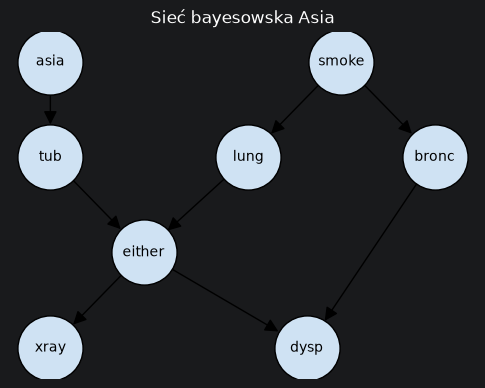

In [3]:
import matplotlib.pyplot as plt
import networkx as nx


pos = {
    "asia": (0, 3), "smoke": (2.5, 3),
    "tub": (0, 2), "lung": (1.7, 2), "bronc": (3.3, 2),
    "either": (0.8, 1),
    "xray": (0, 0), "dysp": (2.2, 0),
}

plt.figure(figsize=(6, 4.5))
nx.draw_networkx(asia_model, pos=pos, node_size=2200, node_color="#cfe2f3",
                 edgecolors="k", arrowsize=20, font_size=10)
plt.axis("off")
plt.title("Sieć bayesowska Asia")
plt.show()


## 1.2 Weryfikacja CDP

In [11]:
for cpd in asia_model.get_cpds():
    print(cpd, end="\n\n")


+-----------+------+
| asia(yes) | 0.01 |
+-----------+------+
| asia(no)  | 0.99 |
+-----------+------+

+----------+-----------+----------+
| asia     | asia(yes) | asia(no) |
+----------+-----------+----------+
| tub(yes) | 0.05      | 0.01     |
+----------+-----------+----------+
| tub(no)  | 0.95      | 0.99     |
+----------+-----------+----------+

+------------+-----+
| smoke(yes) | 0.5 |
+------------+-----+
| smoke(no)  | 0.5 |
+------------+-----+

+-----------+------------+-----------+
| smoke     | smoke(yes) | smoke(no) |
+-----------+------------+-----------+
| lung(yes) | 0.1        | 0.01      |
+-----------+------------+-----------+
| lung(no)  | 0.9        | 0.99      |
+-----------+------------+-----------+

+------------+------------+-----------+
| smoke      | smoke(yes) | smoke(no) |
+------------+------------+-----------+
| bronc(yes) | 0.6        | 0.3       |
+------------+------------+-----------+
| bronc(no)  | 0.4        | 0.7       |
+------------+-------

## 1.3 Przykładowe Zapytania

In [12]:
from pgmpy.example_models import load_model
from pgmpy.inference import VariableElimination

loaded_asia_model = load_model("bnlearn/asia")
loaded_asia_infer = VariableElimination(loaded_asia_model)

asia_infer = VariableElimination(asia_model)

queries = [
{"variables": ["bronc"], "evidence": {"smoke":"no"}},
{"variables": ["bronc", "asia"], "evidence": {"smoke":"yes"}},
{"variables": ["bronc", "asia"], "evidence": {"smoke":"no"}},
]

for idx, q in enumerate(queries, start=1):
    print(f"# {idx} query")
    print("Loaded Model")
    print(loaded_asia_infer.query(variables=q["variables"], evidence=q["evidence"]))
    print("My Model")
    print(asia_infer.query(variables=q["variables"], evidence=q["evidence"]))
    print()
    print()

# 1 query
Loaded Model
+------------+--------------+
| bronc      |   phi(bronc) |
+============+==============+
| bronc(yes) |       0.3000 |
+------------+--------------+
| bronc(no)  |       0.7000 |
+------------+--------------+
My Model
+------------+--------------+
| bronc      |   phi(bronc) |
+============+==============+
| bronc(yes) |       0.3000 |
+------------+--------------+
| bronc(no)  |       0.7000 |
+------------+--------------+


# 2 query
Loaded Model
+------------+-----------+-------------------+
| bronc      | asia      |   phi(bronc,asia) |
+============+===========+===================+
| bronc(yes) | asia(yes) |            0.0060 |
+------------+-----------+-------------------+
| bronc(yes) | asia(no)  |            0.5940 |
+------------+-----------+-------------------+
| bronc(no)  | asia(yes) |            0.0040 |
+------------+-----------+-------------------+
| bronc(no)  | asia(no)  |            0.3960 |
+------------+-----------+-------------------+
My Mod

# 2. Rozszerzenie modelu

In [13]:
asia_model.add_edge('bronc', 'cough')
asia_model.add_edge('either', 'cough')


cdp_cough = TabularCPD(
    variable="cough",
    variable_card=2,
    # Columns: either=[yes, no] | Rows: xray=[yes, no]
    # [ (yes,yes), (yes,no), (no,yes), (no,no) ]
    values=[
        [0.95, 0.7, 0.9, 0.5],  # yes
        [0.05, 0.3, 0.1, 0.5]   # no
    ],
    evidence=["bronc", "either"],
    evidence_card=[2, 2],
    state_names={
        "cough": ["yes", "no"],
        "bronc": ["yes", "no"],
        "either": ["yes", "no"],
    }
)

asia_model.add_cpds(cdp_cough)

asia_model.check_model()

True

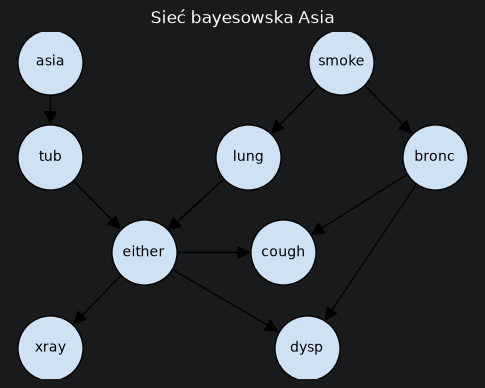

In [14]:
pos = {
    "asia": (0, 3), "smoke": (2.5, 3),
    "tub": (0, 2), "lung": (1.7, 2), "bronc": (3.3, 2),
    "either": (0.8, 1),
    "xray": (0, 0), "dysp": (2.2, 0), "cough":(2, 1)
}

plt.figure(figsize=(6, 4.5))
nx.draw_networkx(asia_model, pos=pos, node_size=2200, node_color="#cfe2f3",
                 edgecolors="k", arrowsize=20, font_size=10)
plt.axis("off")
plt.title("Sieć bayesowska Asia")
plt.show()


## 2.1 Diagnoza Pacjenta
Dodaj do sieci nową zmienną, np. `cough` (kaszel), zależną od `bronc` i `either`, z samodzielnie zaproponowanymi CPD. Jak obserwacja kaszlu zmienia diagnozę dla pacjenta z rozdziału 4.2?

In [17]:
import pandas as pd


asia_infer = VariableElimination(asia_model)
diseases = ["tub", "lung", "bronc"]

def diagnose(evidence):
    # Zwraca P(choroba = yes | evidence) dla każdej choroby
    q = asia_infer.query(variables=diseases, evidence=evidence, joint=False)
    return {d: round(q[d].get_value(**{d: "yes"}), 4) for d in diseases}


scenarios = {
    "brak informacji": {},
    "duszność": {"dysp": "yes"},
    "duszność + pali": {"dysp": "yes", "smoke": "yes"},
    "duszność + pali + RTG nieprawidłowe": {"dysp": "yes", "smoke": "yes", "xray": "yes"},
    "duszność + pali + RTG nieprawidłowe + Azja": {"dysp": "yes", "smoke": "yes", "xray": "yes", "asia": "yes"},
}


scenarios_with_cough = {
    "kaszel": {"cough": "yes"},
    "kaszel + duszność": {"cough": "yes", "dysp": "yes"},
    "kaszel +duszność + pali": {"cough": "yes", "dysp": "yes", "smoke": "yes"},
    "kaszel +duszność + pali + RTG nieprawidłowe": {"cough": "yes", "dysp": "yes", "smoke": "yes", "xray": "yes"},
    "kaszel +duszność + pali + RTG nieprawidłowe + Azja": {"cough": "yes", "dysp": "yes", "smoke": "yes", "xray": "yes", "asia": "yes"},
}


diag = pd.DataFrame({name: diagnose(ev) for name, ev in scenarios.items()}).T
print(diag)
print()

diag_c = pd.DataFrame({name: diagnose(ev) for name, ev in scenarios_with_cough.items()}).T
print(diag_c)

                                               tub    lung   bronc
brak informacji                             0.0104  0.0550  0.4500
duszność                                    0.0188  0.1028  0.8340
duszność + pali                             0.0154  0.1483  0.8802
duszność + pali + RTG nieprawidłowe         0.0753  0.7237  0.7137
duszność + pali + RTG nieprawidłowe + Azja  0.2896  0.5792  0.7009

                                                       tub    lung   bronc
kaszel                                              0.0157  0.0837  0.5306
kaszel + duszność                                   0.0248  0.1360  0.8556
kaszel +duszność + pali                             0.0199  0.1909  0.8868
kaszel +duszność + pali + RTG nieprawidłowe         0.0797  0.7662  0.7149
kaszel +duszność + pali + RTG nieprawidłowe + Azja  0.3025  0.6050  0.7041


# 3. Analiza Wrażliwości
Zbadaj, jak $P(\text{lung}=\text{yes} \mid \text{xray}=\text{yes}, \text{dysp}=\text{yes}, \text{smoke}=\text{yes})$ zależy od czułości RTG, tj. od $P(\text{xray}=\text{yes} \mid \text{either}=\text{yes})$ zmienianego w zakresie 0,5–1. Przedstaw wynik na wykresie.

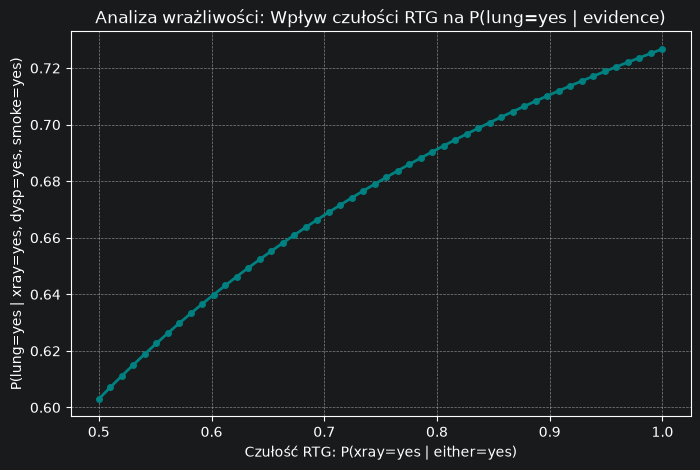

In [18]:
import numpy as np

cdp_xray = asia_model.get_cpds('xray')
state_names = cdp_xray.state_names
original_values = cdp_xray.get_values()

sensitivities = np.linspace(0.5, 1.0, 50)
probs = []

infer = VariableElimination(asia_model)
for s in sensitivities:
    new_values = original_values.copy()

    new_values[0, 0] = s       # P(xray=yes | either=yes)
    new_values[1, 0] = 1 - s   # P(xray=no | either=yes)

    updated_cpd = TabularCPD(
        variable='xray',
        variable_card=2,
        values=new_values,
        evidence=['either'],
        evidence_card=[2],
        state_names=state_names
    )

    asia_model.add_cpds(updated_cpd)

    result = infer.query(
        variables=['lung'],
        evidence={'xray': 'yes', 'dysp': 'yes', 'smoke': 'yes'}
    )

    lung_states = asia_model.get_cpds('lung').state_names['lung']
    lung_yes_idx = lung_states.index('yes')
    prob = result.values[lung_yes_idx]
    probs.append(prob)

plt.figure(figsize=(8, 5))
plt.plot(sensitivities, probs, marker='o', color='teal', linewidth=2, markersize=4)
plt.title("Analiza wrażliwości: Wpływ czułości RTG na P(lung=yes | evidence)")
plt.xlabel("Czułość RTG: P(xray=yes | either=yes)")
plt.ylabel("P(lung=yes | xray=yes, dysp=yes, smoke=yes)")
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

## 3.1 Przywrócenie oryginalnego cdp

In [19]:
asia_model.add_cpds(cdp_xray)

# 4. Wartość informacji
Lekarz może zlecić tylko jedno badanie: RTG (`xray`) albo zapytać o pobyt w Azji (`asia`). Dla pacjenta z dusznością, który pali, oblicz oczekiwany spadek entropii rozkładu `tub` po poznaniu każdej z tych zmiennych. Która informacja jest cenniejsza?

In [20]:
def compute_entropy(probs):
  """Oblicza entropię Shannona w bitach dla danego wektora prawdopodobieństw."""
  probs = np.array(probs)
  probs = probs[probs > 0]  # Eliminacja zer, aby uniknąć log(0)
  return -np.sum(probs * np.log2(probs))


def expected_entropy_reduction(model, infer, target, test_var, evidence):
  # Rozkład zmiennej testowej przy obecnych dowodach: P(Y | E)
  q_test = infer.query(variables=[test_var], evidence=evidence)
  states = model.get_cpds(test_var).state_names[test_var]

  expected_h_posterior = 0.0

  # Warunkowanie po każdym możliwym stanie zmiennej testowej y
  for state, p_y in zip(states, q_test.values):
    if p_y > 0:
      new_evidence = evidence.copy()
      new_evidence[test_var] = state

      # P(tub | E, Y = state)
      q_posterior = infer.query(variables=[target], evidence=new_evidence)
      h_posterior = compute_entropy(q_posterior.values)

      expected_h_posterior += p_y * h_posterior

  # Information Gain = H(initial) - E[H(posterior)]
  h_initial = compute_entropy(
      infer.query(variables=[target], evidence=evidence).values
  )
  return h_initial - expected_h_posterior


## 4.1 Dowód w postacia zmiennej `asia`

In [22]:
target_var = 'tub'
test_var = 'asia'
current_evidence = {}

gain = expected_entropy_reduction(
    model = asia_model,
    infer = asia_infer,
    target=target_var,
    test_var=test_var,
    evidence=current_evidence
)

print(f"Gain for asia: {gain}")

Gain for asia: 0.0005841971600548945


## 4.2 Dowód w postaci zmiennej `xray`

In [23]:
target_var = 'tub'
test_var = 'xray'
current_evidence = {}

gain = expected_entropy_reduction(
    model = asia_model,
    infer = asia_infer,
    target=target_var,
    test_var=test_var,
    evidence=current_evidence
)

print(f"Gain for xray: {gain}")


Gain for xray: 0.03160411850261094


Zmienna `xray` cechuje się znacznie wyższym przypływem informacji, niż zmienna `asia`

# 5. Uczenie z Małej Próby
Powtórz eksperyment z rozdziału 6 dla zbiorów o liczności 100, 500, 2000, 10000 i 50000. Narysuj błąd zapytania $P(\text{tub}=\text{yes}\mid \text{asia}=\text{yes}, \text{xray}=\text{yes})$ w funkcji liczności zbioru dla MLE i estymatora bayesowskiego (dla kilku wartości `equivalent_sample_size`).

In [ ]:
##TODO: Powtórzyć eksperyment z pgmpy_intro 6.

In [24]:
data = asia_model.simulate(n_samples=5000, seed=42)
data.head()

Generating for node: cough: 100%|██████████| 9/9 [00:00<00:00, 195.51it/s]


,dysp,lung,xray,asia,bronc,cough,either,tub,smoke
0,yes,no,no,no,yes,yes,no,no,yes
1,yes,yes,yes,no,yes,yes,yes,no,yes
2,no,no,no,no,no,yes,no,no,no
3,yes,no,no,no,no,yes,no,no,yes
4,yes,no,no,no,yes,yes,no,no,no


## Estymator Największej Wiarygodności (MLE)

In [38]:
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.parameter_estimator import DiscreteMLE

mle_model = DiscreteBayesianNetwork(asia_model.edges())  # tylko struktura, bez CPD
mle_model.fit(data, estimator=DiscreteMLE())

print(asia_model.get_cpds("tub"))
print(mle_model.get_cpds("tub"))

+----------+-----------+----------+
| asia     | asia(yes) | asia(no) |
+----------+-----------+----------+
| tub(yes) | 0.05      | 0.01     |
+----------+-----------+----------+
| tub(no)  | 0.95      | 0.99     |
+----------+-----------+----------+
+----------+----------------------+----------------------+
| asia     | asia(no)             | asia(yes)            |
+----------+----------------------+----------------------+
| tub(no)  | 0.9899091826437941   | 0.9777777777777777   |
+----------+----------------------+----------------------+
| tub(yes) | 0.010090817356205853 | 0.022222222222222223 |
+----------+----------------------+----------------------+


## Estymator Bayesowski

In [39]:
from pgmpy.parameter_estimator import DiscreteBayesianEstimator

bayes_model = DiscreteBayesianNetwork(asia_model.edges())
bayes_model.fit(data, estimator=DiscreteBayesianEstimator(prior_type="BDeu", equivalent_sample_size=10))

print(bayes_model.get_cpds("tub"))
print(bayes_model.get_cpds("either"))

+----------+----------------------+-----------+
| asia     | asia(no)             | asia(yes) |
+----------+----------------------+-----------+
| tub(no)  | 0.9894153225806451   | 0.93      |
+----------+----------------------+-----------+
| tub(yes) | 0.010584677419354838 | 0.07      |
+----------+----------------------+-----------+
+-------------+-----+---------------------+
| lung        | ... | lung(yes)           |
+-------------+-----+---------------------+
| tub         | ... | tub(yes)            |
+-------------+-----+---------------------+
| either(no)  | ... | 0.22727272727272727 |
+-------------+-----+---------------------+
| either(yes) | ... | 0.7727272727272727  |
+-------------+-----+---------------------+


## Porównanie

In [40]:
test_queries = [
    ("lung", {"xray": "yes", "dysp": "yes"}),
    ("tub", {"asia": "yes", "xray": "yes"}),
    ("bronc", {"smoke": "yes", "dysp": "yes"}),
    ("tub", {"xray": "yes", "lung": "no"}),
]
rows = []
for var, ev in test_queries:
    row = {"zapytanie": f"P({var}=yes | {ev})"}
    for name, model in [("oryginał", asia_model), ("MLE", mle_model), ("Bayes (BDeu)", bayes_model)]:
        row[name] = VariableElimination(model).query([var], evidence=ev).get_value(**{var: "yes"})
    rows.append(row)
pd.DataFrame(rows).set_index("zapytanie").round(4)


,oryginał,MLE,Bayes (BDeu)
zapytanie,,,
"P(lung=yes | {'xray': 'yes', 'dysp': 'yes'})",0.6213,0.6260,0.6183
"P(tub=yes | {'asia': 'yes', 'xray': 'yes'})",0.3377,0.1820,0.4119
"P(bronc=yes | {'smoke': 'yes', 'dysp': 'yes'})",0.8802,0.8812,0.8806
"P(tub=yes | {'xray': 'yes', 'lung': 'no'})",0.1708,0.1707,0.1773
